# 08 · Consumo de ATP y acoplamiento mecanoquímico

Contaremos eventos de hidrólisis, pasos hacia delante y hacia atrás. En el modelo actual, la transición de hidrólisis consume una molécula de ATP; el cierre mecánico del ciclo ocurre en un evento posterior.

> **ProteinMotorSim 0.1.1** · Ejemplo educativo. Las tasas predeterminadas del modelo son ilustrativas y no representan todavía una parametrización experimental validada.

## Preparación del entorno

Esta celda localiza automáticamente la raíz del repositorio e incorpora `src/` a la ruta de importación. Instala antes las dependencias con `python -m pip install -e ".[dev,viz]"` y selecciona el kernel `Python (ProteinMotorSim)`.

In [1]:
from pathlib import Path
import sys

# Busca la raíz del proyecto desde el directorio actual o sus carpetas padre.
_candidates = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next(
    (path for path in _candidates if (path / "pyproject.toml").exists() and (path / "src").is_dir()),
    None,
)

if PROJECT_ROOT is None:
    raise RuntimeError(
        "No se encontró ProteinMotorSim. Abre JupyterLab desde la carpeta raíz "
        "del proyecto o desde su carpeta notebooks/."
    )

sys.path.insert(0, str(PROJECT_ROOT / "src"))
print(f"Proyecto detectado: {PROJECT_ROOT}")

Proyecto detectado: /home/zix/ProteinMotorSim


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

from protein_motor_sim import Environment, GillespieSimulator, Kinesin1
from protein_motor_sim.simulation.ensemble import run_ensemble

ensemble = run_ensemble(
    GillespieSimulator(), Kinesin1(),
    Environment(atp_concentration=1.0e-3),
    t_max=0.5, n_runs=80, seed=888,
)

## 1. Contar eventos por trayectoria

In [3]:
rows = []
for trajectory in ensemble.trajectories:
    counts = Counter(trajectory.events)
    hydrolysis = counts["atp_hydrolysis"]
    forward = counts["forward_step"]
    backward = counts["backward_step"]
    rows.append({
        "atp": trajectory.atp_consumed_total,
        "hydrolysis": hydrolysis,
        "forward": forward,
        "backward": backward,
        "net_steps": forward - backward,
        "detached": trajectory.final_state == "detached",
    })

for key in ("atp", "hydrolysis", "forward", "backward", "net_steps"):
    print(f"{key:12s}: media={np.mean([row[key] for row in rows]):.3f}")

atp         : media=20.863
hydrolysis  : media=20.863
forward     : media=20.300
backward    : media=0.025
net_steps   : media=20.275


## 2. Relación pasos / hidrólisis

Media de pasos por hidrólisis (solo trayectorias con hidrólisis): 0.9732457427406687


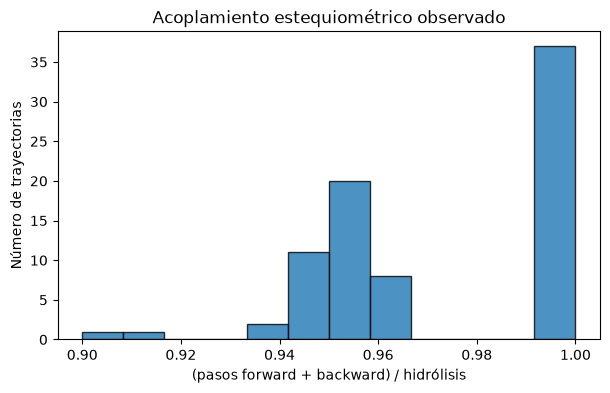

In [4]:
ratios = [
    (row["forward"] + row["backward"]) / row["hydrolysis"]
    for row in rows if row["hydrolysis"] > 0
]
print("Media de pasos por hidrólisis (solo trayectorias con hidrólisis):", np.mean(ratios))

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(ratios, bins=12, edgecolor="black", alpha=0.8)
ax.set_xlabel("(pasos forward + backward) / hidrólisis")
ax.set_ylabel("Número de trayectorias")
ax.set_title("Acoplamiento estequiométrico observado")
plt.show()

## 3. Desplazamiento por ATP consumido

In [5]:
displacement_per_atp = [
    trajectory.displacement_nm / trajectory.atp_consumed_total
    for trajectory in ensemble.trajectories
    if trajectory.atp_consumed_total > 0
]
print("Desplazamiento neto/ATP (nm por molécula):", np.mean(displacement_per_atp))
print("Paso nominal configurado (nm):", Kinesin1().step_size_nm)

Desplazamiento neto/ATP (nm por molécula): 7.9630969086553
Paso nominal configurado (nm): 8.2


**Limitación del modelo:** no existe todavía un mecanismo explícito de coordinación de las dos cabezas. El cociente anterior describe la contabilidad de eventos de esta red simplificada; no debe interpretarse como una medición experimental de eficiencia energética.